# 05 · Modelado y comparación (Fase 7)

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.max_columns", 30)
from src.config import *
df = pd.read_parquet(PROCESSED / "emovi_movilidad.parquet")
q1 = df[df.sigue_q1.notna()]
from src.models import train as T
tr, te = T.split(df)
tabla, modelos = T.compare(tr, te, T.NUM, T.CAT)
elegido, mejor_auc = T.choose(tabla)
modelo = modelos[elegido]
from src.visualization import plots as V
import matplotlib.pyplot as plt

,Modelo,AUC CV (media),AUC CV (desv.),AUC prueba,Exactitud balanceada prueba,F1 prueba,Brier prueba
0,Base: siempre la clase mayoritaria,0.500,0.000,0.500,0.500,0.682,0.250
1,Base: sólo índice de origen,0.531,0.022,0.556,0.533,0.642,0.248
2,Regresión logística,0.696,0.011,0.716,0.670,0.683,0.214
3,Árbol de decisión,0.652,0.028,0.681,0.655,0.673,0.226
4,Random forest,0.690,0.014,0.722,0.652,0.679,0.219
5,Gradient boosting,0.672,0.006,0.721,0.659,0.671,0.213


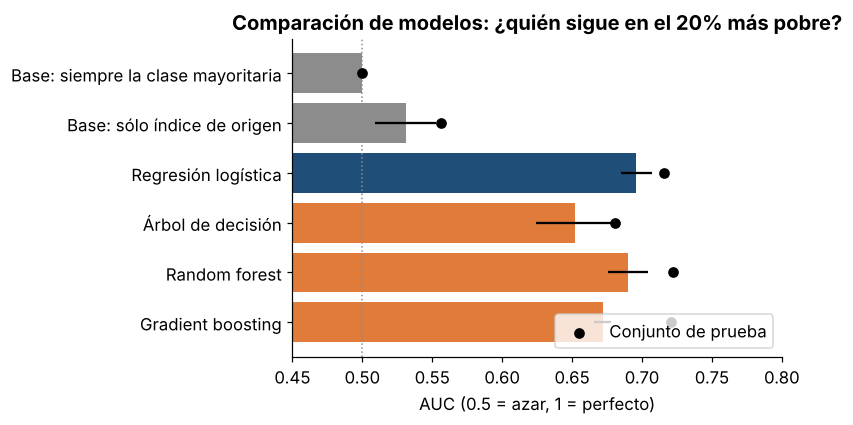

Modelo con mayor AUC en CV: Regresión logística | Modelo elegido: Regresión logística


In [2]:
tabla.to_csv(TABLES / "comparacion_modelos.csv", index=False)
display(tabla); V.comparacion_modelos(tabla); plt.show()
print("Modelo con mayor AUC en CV:", mejor_auc, "| Modelo elegido:", elegido)

## Decisión
La regresión logística tiene el mejor AUC en validación cruzada (≈0.70), es estable (desviación ≈0.01) y es interpretable. Random forest y gradient boosting quedan prácticamente empatados en el conjunto de prueba (±0.01), pero son más inestables en CV. **Se elige la regresión logística** (regla congelada en el notebook 00).

## Modelo de mediación: ¿cuánto agrega la escolaridad propia?

In [3]:
tabla_med, _ = T.compare(tr, te, T.NUM + T.MEDIADORAS_NUM, T.CAT + T.MEDIADORAS_CAT)
tabla_med.to_csv(TABLES / "comparacion_modelos_mediacion.csv", index=False)
comp = pd.DataFrame({"Solo origen": tabla.set_index("Modelo")["AUC CV (media)"], "Origen + escolaridad propia + migración": tabla_med.set_index("Modelo")["AUC CV (media)"]})
display(comp)

,Solo origen,Origen + escolaridad propia + migración
Modelo,,
Base: siempre la clase mayoritaria,0.500,0.500
Base: sólo índice de origen,0.531,0.531
Regresión logística,0.696,0.737
Árbol de decisión,0.652,0.685
Random forest,0.690,0.729
Gradient boosting,0.672,0.720


**Lectura:** agregar la escolaridad propia sube el AUC de ≈0.70 a ≈0.74. La educación es una de las vías por las que se sale del fondo, pero es una **trayectoria**, no una circunstancia de origen. Por eso no entra en el modelo principal.

## Tarea secundaria: movilidad en 3 clases (todas las personas)

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
num3 = T.NUM + []; cat3 = T.CAT + []
d3 = df.assign(q_origen_cat=df.q_origen.astype(str))
a, b = train_test_split(d3, test_size=.2, stratify=d3.movilidad, random_state=SEED)
m3 = Pipeline([("p", T.preprocessor(num3, cat3 + ["q_origen_cat"])), ("m", LogisticRegression(max_iter=5000))]).fit(a[num3+cat3+["q_origen_cat"]], a.movilidad)
print(classification_report(b.movilidad, m3.predict(b[num3+cat3+["q_origen_cat"]]), digits=3))

              precision    recall  f1-score   support

     Ascenso      0.493     0.545     0.518       990
    Descenso      0.530     0.644     0.582      1217
 Permanencia      0.575     0.421     0.486      1362

    accuracy                          0.532      3569
   macro avg      0.533     0.537     0.529      3569
weighted avg      0.537     0.532     0.528      3569



**Lectura:** predecir ascenso, permanencia o descenso para toda la población es más difícil y depende mucho del quintil de origen (quien está en Q1 no puede descender). Por eso el reporte se centra en la tarea binaria, que responde directamente a la pregunta de la pobreza pegajosa.